### **Introduction**

In this assignment, we study community detection using the Karate Club graph. It is a social network with 34 nodes and 78 edges.

Our main aim is to divide the network into smaller communities using the spectral modularity method. We also calculate different network measures such as degree centrality, betweenness centrality, closeness centrality and clustering coefficient.

Step 1: Importing Libraries

In [38]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

Step 2: Loading Karate club Graph from NetworkX

In [39]:
G= nx.karate_club_graph()
G1=G.copy()
print("No of nodes :", G1.number_of_nodes())
print("No of edges :", G1.number_of_edges())

No of nodes : 34
No of edges : 78


Step 3: Visualizing the code

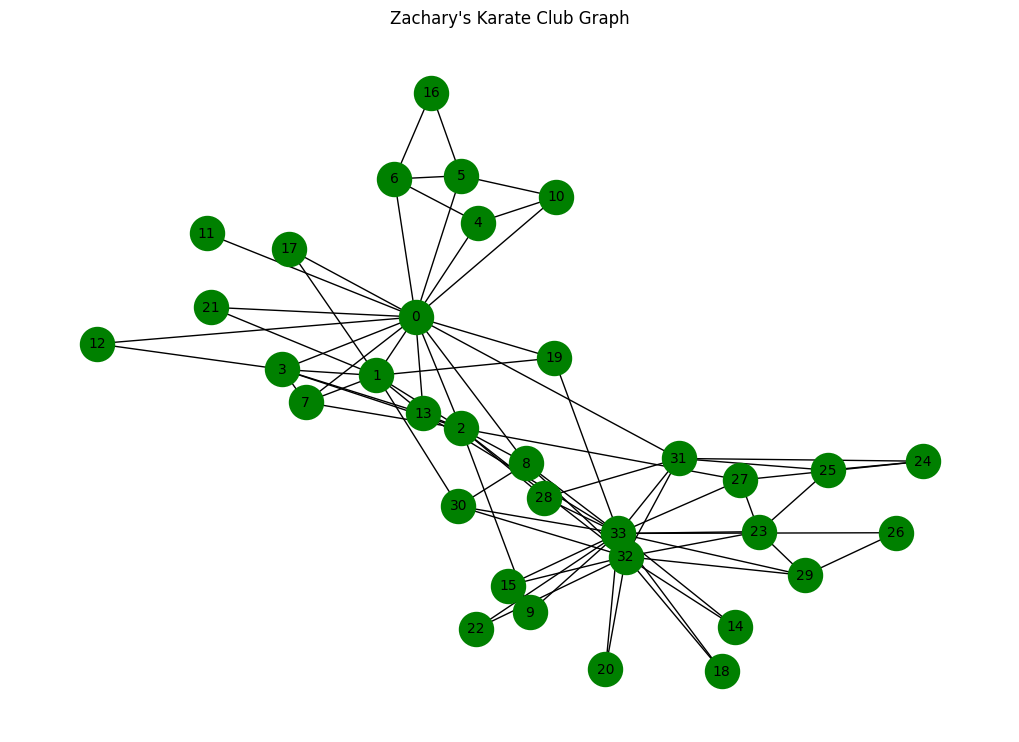

In [40]:
pos = nx.spring_layout(G1, seed=42)
plt.figure(figsize=(10, 7))
nx.draw(G1, pos, with_labels=True, node_color='green', node_size=600, font_size=10, edge_color='black')
plt.title("Zachary's Karate Club Graph")
plt.show()

Step 4: Constructiong Modularity Matrix



In [41]:
A = nx.to_numpy_array(G1, weight=None)

print("Shape of adjacency matrix:", A.shape)
print("\nAdjacency matrix:")
print(A)

k = np.sum(A, axis=1)
m = G1.number_of_edges()
print("\nDegree vector:")
print(k)

print("\nTotal number of edges:", m)

B=A- np.outer(k,k)/(2*m)
print("\nModularity Matrix:")
print(B)

Shape of adjacency matrix: (34, 34)

Adjacency matrix:
[[0. 1. 1. ... 1. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [1. 1. 0. ... 0. 1. 0.]
 ...
 [1. 0. 0. ... 0. 1. 1.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]]

Degree vector:
[16.  9. 10.  6.  3.  4.  4.  4.  5.  2.  3.  1.  2.  5.  2.  2.  2.  2.
  2.  3.  2.  2.  2.  5.  3.  3.  2.  4.  3.  4.  4.  6. 12. 17.]

Total number of edges: 78

Modularity Matrix:
[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974 -0.98076923 -1.08974359 ...  0.34615385 -0.30769231
  -1.8525641 ]]


Step 5: Finding the largest Eigenvalue and Eigenvectors

In [42]:
eigenvalues, eigenvectors = np.linalg.eigh(B)
index = np.argmax(eigenvalues)
largest_eigenvalue = eigenvalues[index]
leading_eigenvector = eigenvectors[:, index]

print("Largest eigenvalue:", largest_eigenvalue)
print("\nLeading eigenvector:")
print(leading_eigenvector)

Largest eigenvalue: 4.977080225729887

Leading eigenvector:
[ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]


In [43]:
community_1 = []
community_2 = []

for i in range(len(leading_eigenvector)):
    if leading_eigenvector[i] > 0:
        community_1.append(i)
    else:
        community_2.append(i)

print("Community 1:", community_1)
print("\nCommunity 2:", community_2)

Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]

Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


Step 6: Visualizing the communities

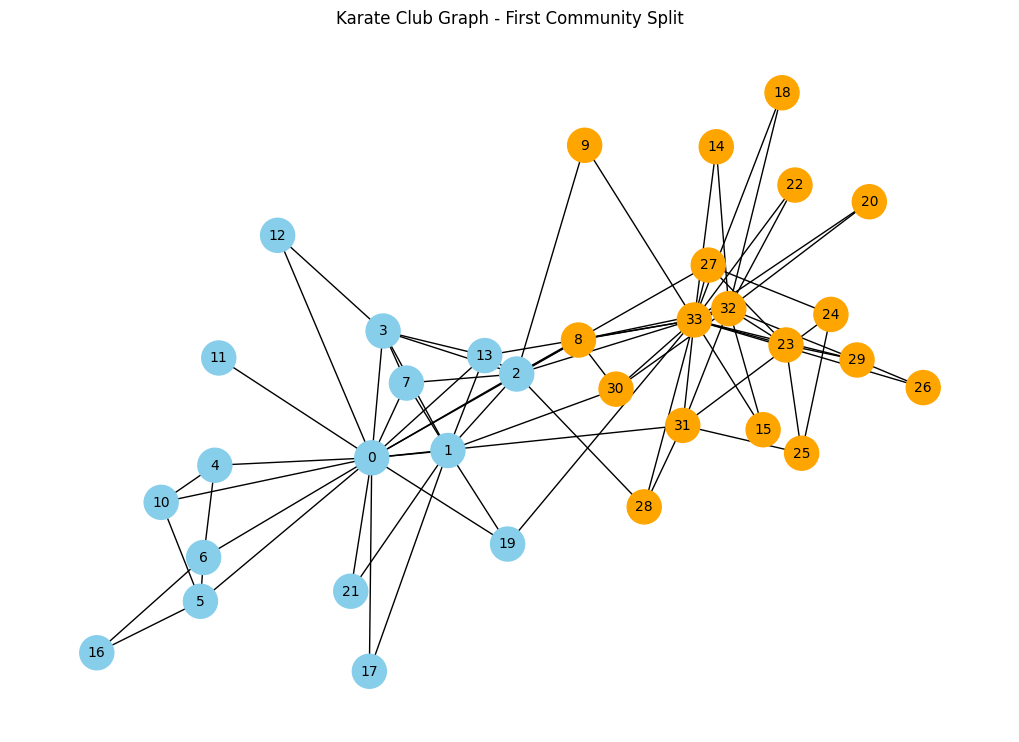

In [44]:
node_colors = []

for node in G1.nodes():
    if node in community_1:
        node_colors.append('skyblue')
    else:
        node_colors.append('orange')

# Visualize the divided graph
pos=nx.spring_layout(G1, seed=42)
plt.figure(figsize=(10, 7))

nx.draw(G1, with_labels=True, node_color=node_colors, node_size=600, font_size=10, edge_color='black'
)

plt.title("Karate Club Graph - First Community Split")
plt.show()

Step 7: Recursive Spectral modularity partitioning

In [45]:
communities = [community_1, community_2]
partition_history = [communities.copy()]

def recursive_partition(community):
    B_sub = B[np.ix_(community, community)]
    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)

    index = np.argmax(eigenvalues)
    largest_eigenvalue = eigenvalues[index]

    if largest_eigenvalue <= 0:
        return

    leading_vector = eigenvectors[:, index]

    group_1 = []
    group_2 = []

    for i in range(len(community)):
        if leading_vector[i] > 0:
            group_1.append(community[i])
        else:
            group_2.append(community[i])

    if len(group_1) == 0 or len(group_2) == 0:
        return

    communities.remove(community)
    communities.extend([group_1, group_2])

    partition_history.append([c.copy() for c in communities])

    recursive_partition(group_1)
    recursive_partition(group_2)


recursive_partition(community_1.copy())
recursive_partition(community_2.copy())

print("Total number of communities:", len(communities))

for i, community in enumerate(communities):
    print(f"Community {i+1}: {community}")

Total number of communities: 5
Community 1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2: [11]
Community 3: [4, 5, 6, 10, 16]
Community 4: [24, 25, 27, 28, 31]
Community 5: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]


Step 8: Visualizing communities after each split

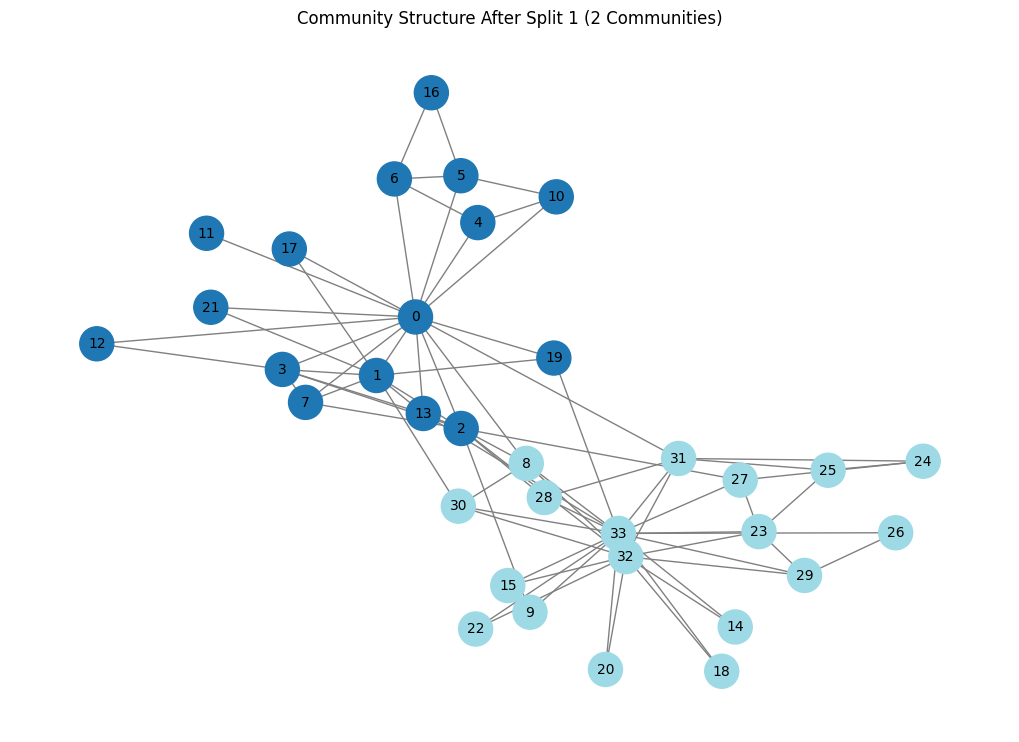

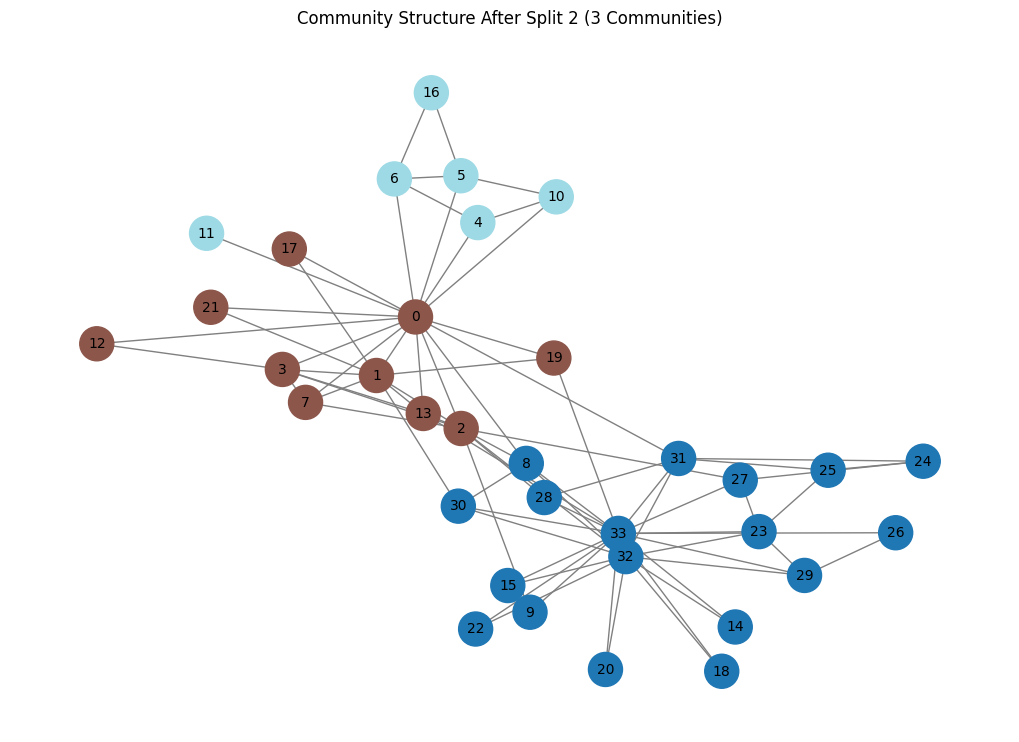

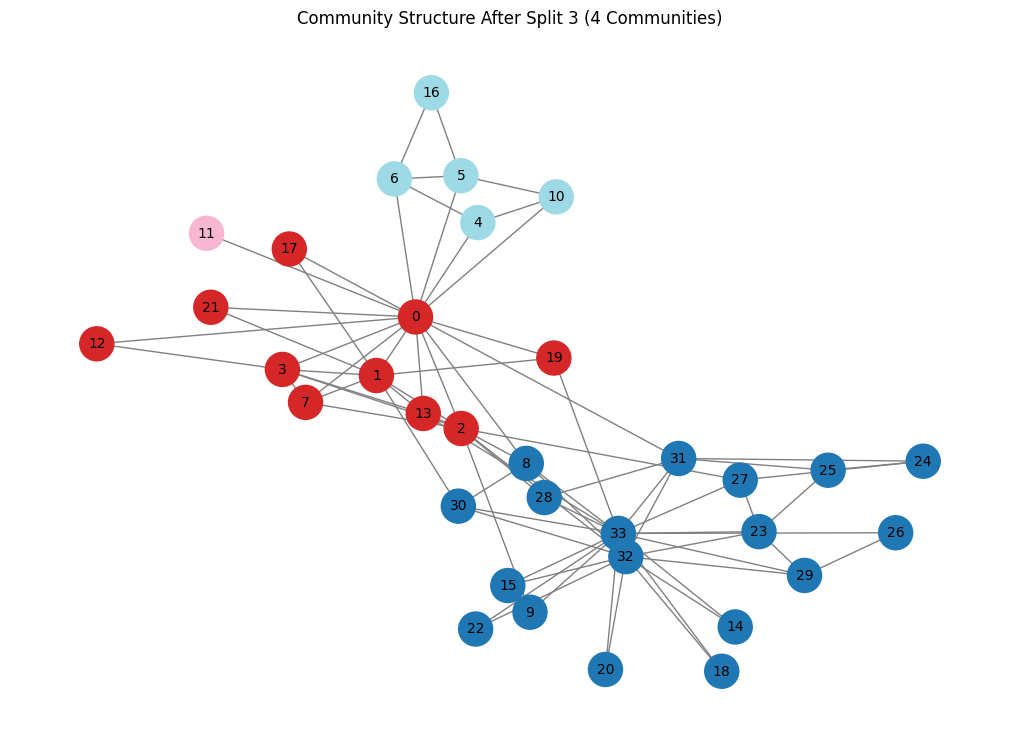

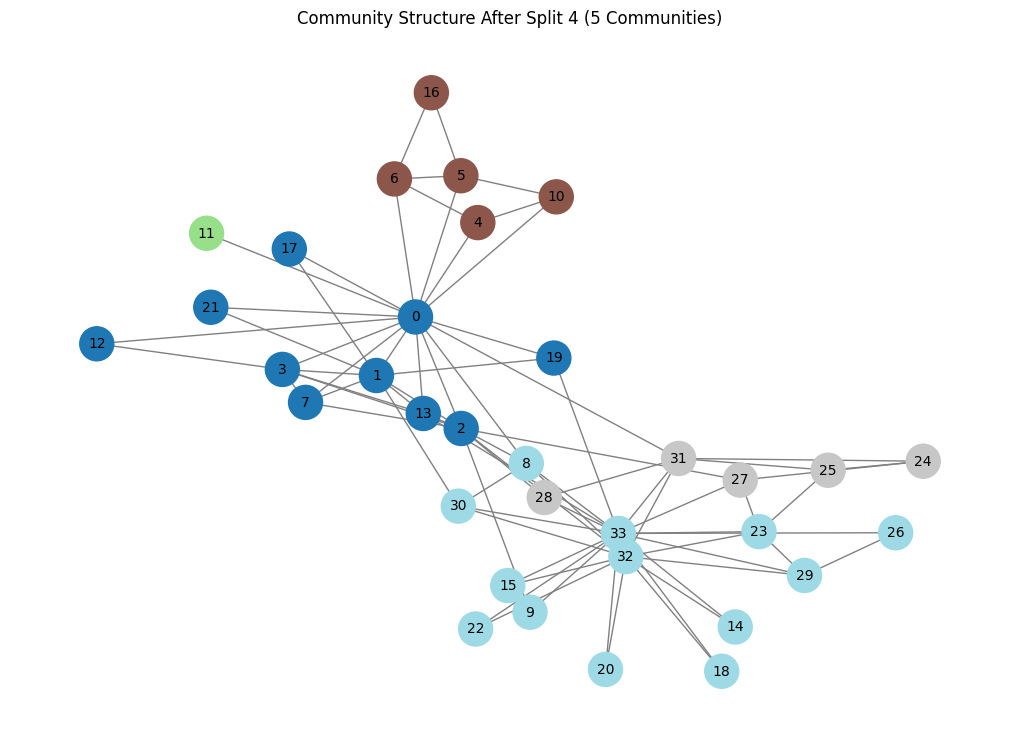

In [46]:

for iteration, partition in enumerate(partition_history):

    plt.figure(figsize=(10, 7))

    node_colors = [0] * G1.number_of_nodes()

    for community_id, community in enumerate(partition):
        for node in community:
            node_colors[node] = community_id

    nx.draw(
        G1,
        pos,
        with_labels=True,
        node_color=node_colors,
        cmap=plt.cm.tab20,
        node_size=600,
        font_size=10,
        edge_color='gray'
    )

    plt.title(
        f"Community Structure After Split {iteration + 1} "
        f"({len(partition)} Communities)"
    )

    plt.show()

Step 9: Calculation of Network Metrics

In [47]:
# Store metric values for every iteration
metrics_history = {
    "Degree Centrality": [],
    "Betweenness Centrality": [],
    "Closeness Centrality": [],
    "Clustering Coefficient": []
}

# Calculate metrics after each split
for iteration, partition in enumerate(partition_history):

    degree_values = {}
    betweenness_values = {}
    closeness_values = {}
    clustering_values = {}

    # Calculate metrics separately for each community
    for community in partition:

        # Create the subgraph containing only this community
        subgraph = G1.subgraph(community).copy()

        # Calculate the four metrics using NetworkX
        degree = nx.degree_centrality(subgraph)
        betweenness = nx.betweenness_centrality(subgraph)
        closeness = nx.closeness_centrality(subgraph)
        clustering = nx.clustering(subgraph)

        # Store the values for each node
        degree_values.update(degree)
        betweenness_values.update(betweenness)
        closeness_values.update(closeness)
        clustering_values.update(clustering)

    # Save the metric values for this iteration
    metrics_history["Degree Centrality"].append(degree_values)
    metrics_history["Betweenness Centrality"].append(betweenness_values)
    metrics_history["Closeness Centrality"].append(closeness_values)
    metrics_history["Clustering Coefficient"].append(clustering_values)

print("Network metrics calculated successfully!")

print("Number of iterations:", len(partition_history))
print("Number of nodes:", G.number_of_nodes())

Network metrics calculated successfully!
Number of iterations: 4
Number of nodes: 34


Step 10 : Evolution of Network Metrics Across Iterations

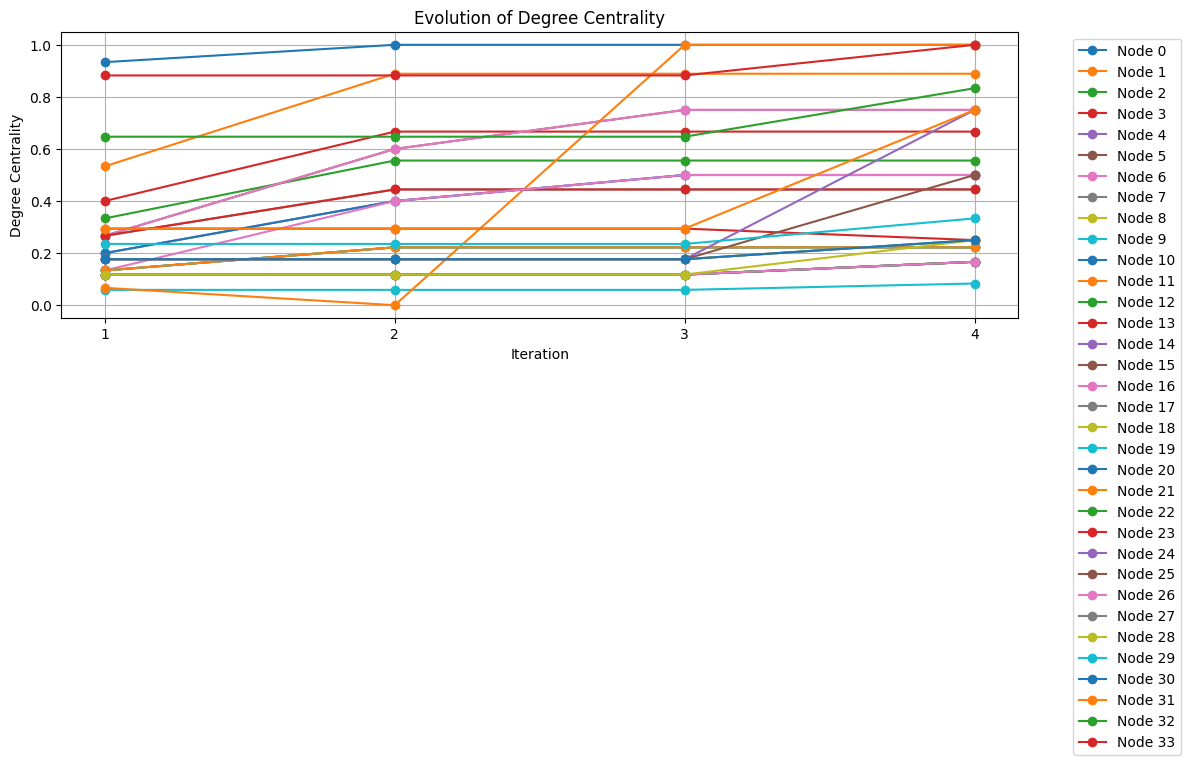

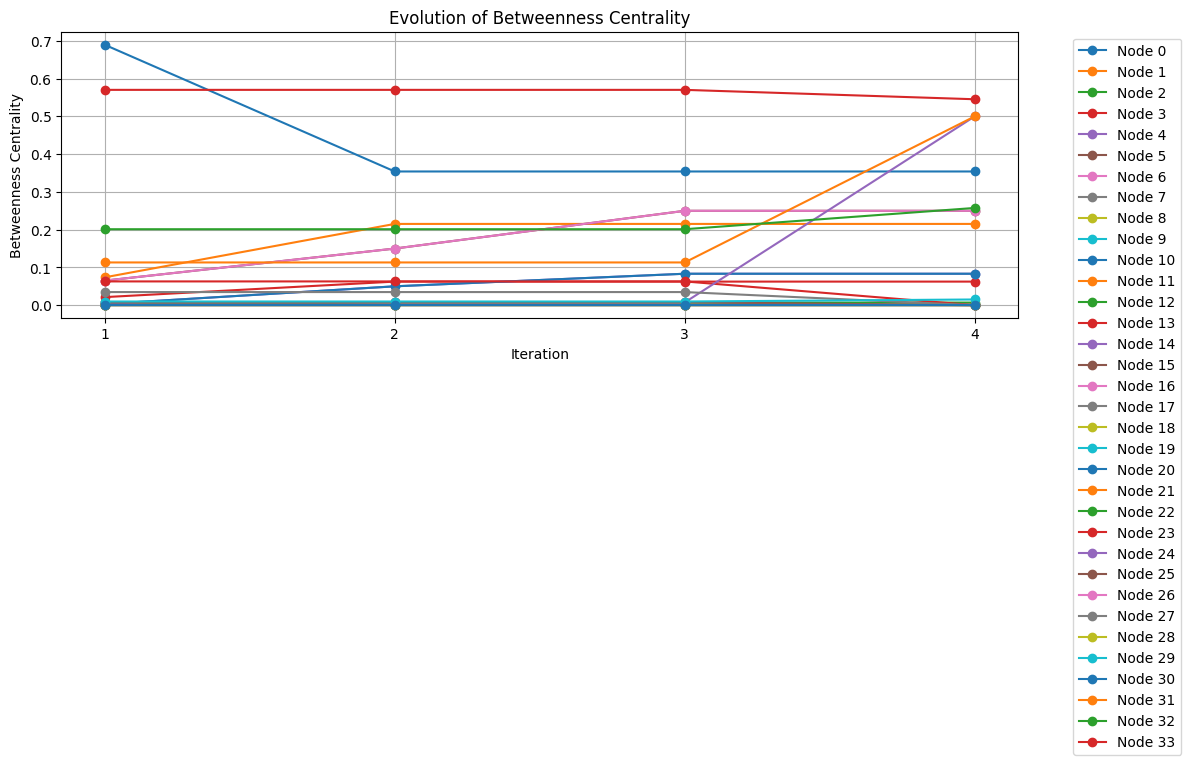

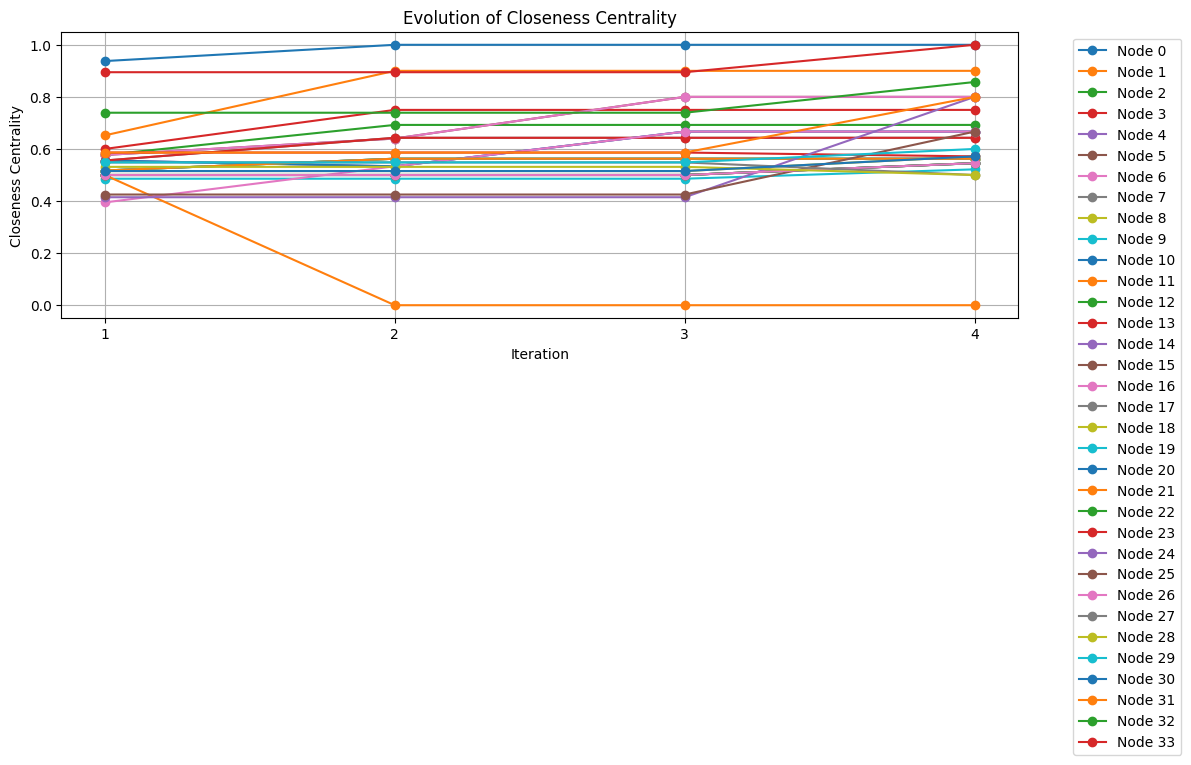

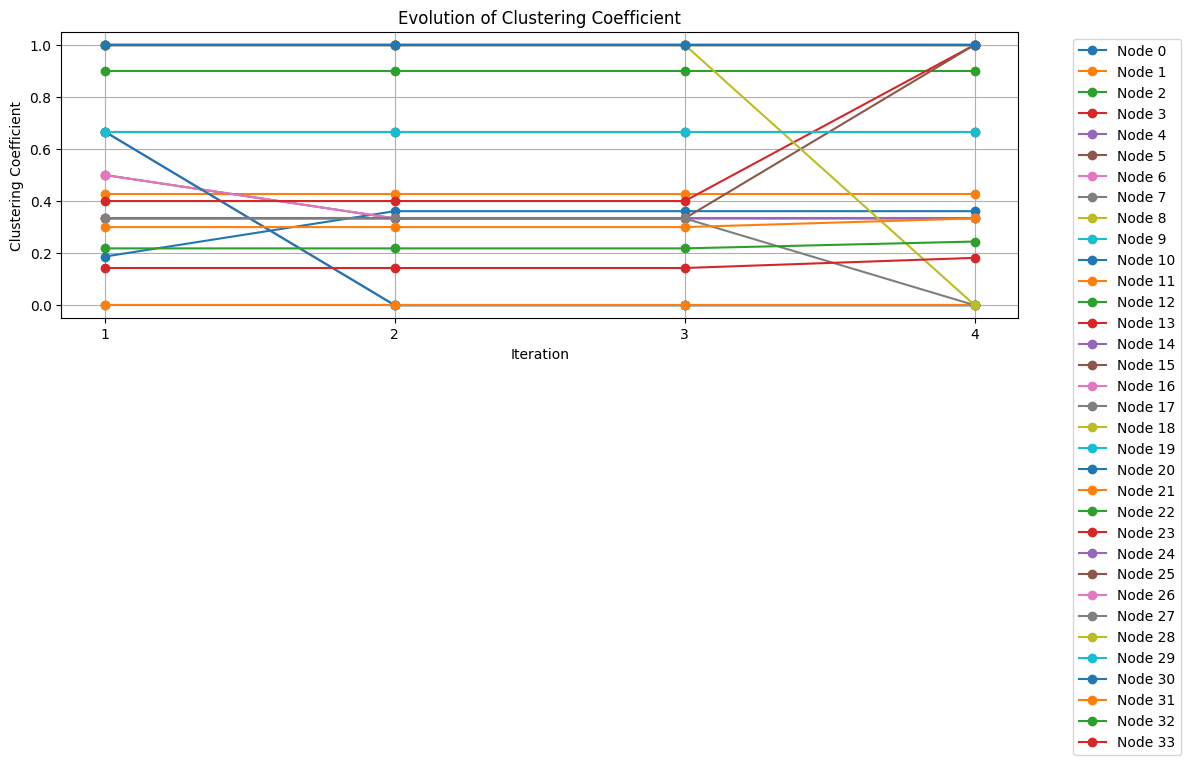

In [48]:
# Plot the evolution of all four network metrics

for metric_name, metric_data in metrics_history.items():

    plt.figure(figsize=(12, 6))

    for node in G1.nodes():

        values = [
            iteration_data[node]
            for iteration_data in metric_data
        ]

        plt.plot(
            range(1, len(values) + 1),
            values,
            marker='o',
            label=f'Node {node}'
        )

    plt.title(f'Evolution of {metric_name}')
    plt.xlabel('Iteration')
    plt.ylabel(metric_name)
    plt.xticks(range(1, len(partition_history) + 1))
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

Step 11 : Plot evolution of the top five nodes for each metric

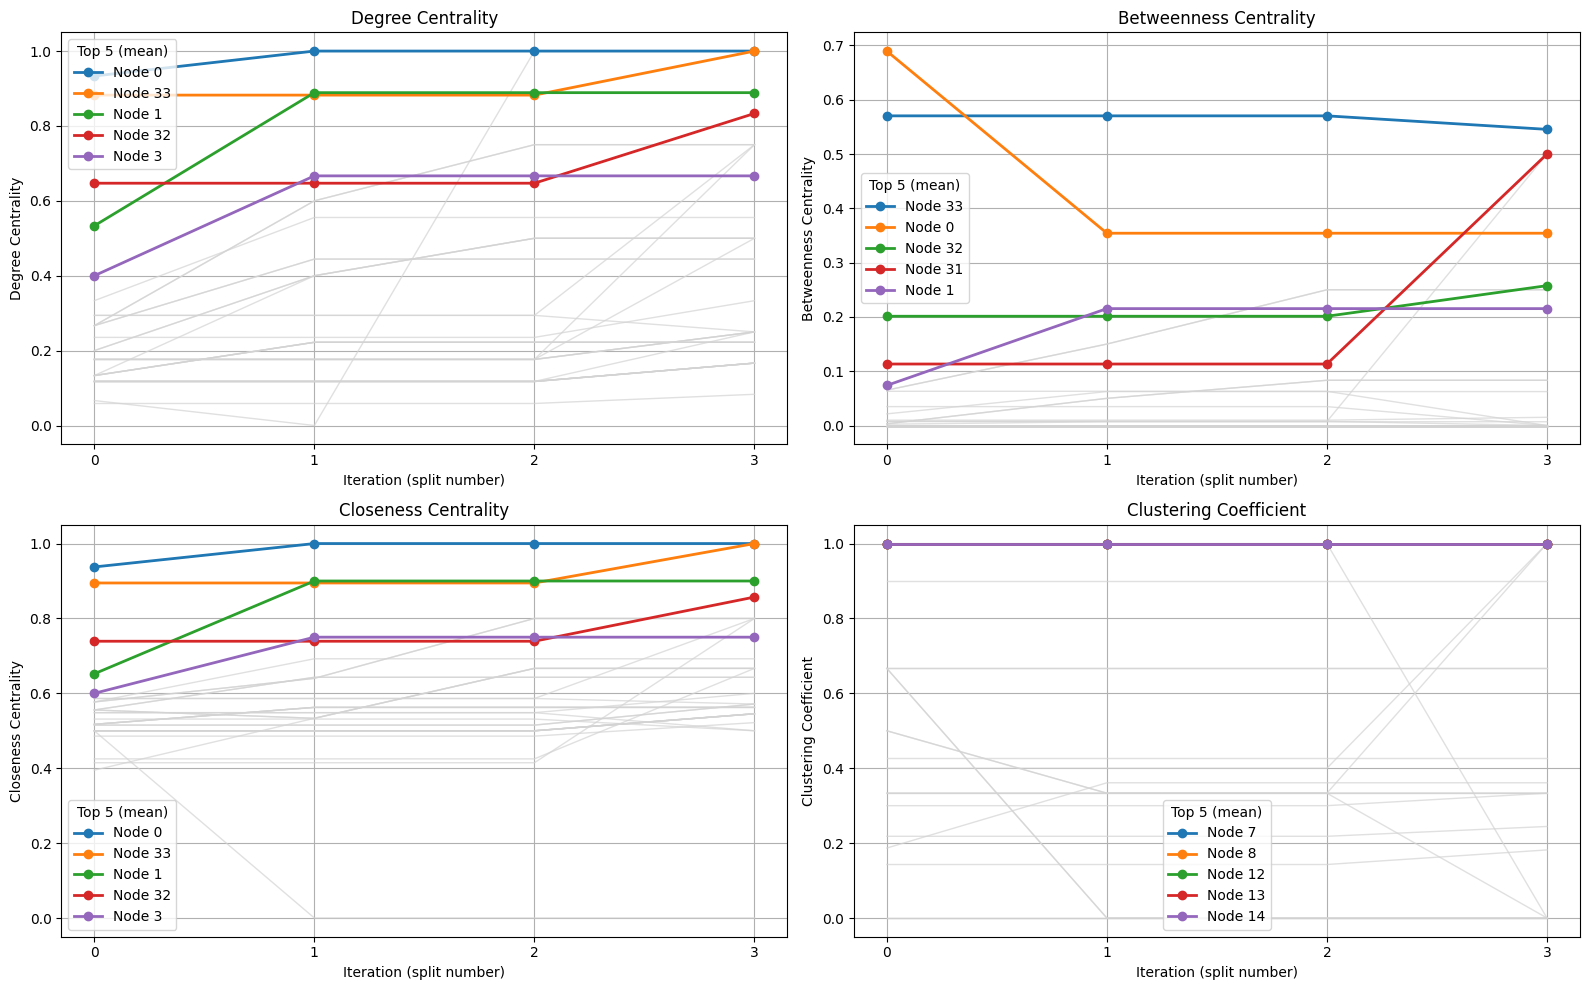

In [49]:


fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, (metric_name, metric_data) in zip(axes, metrics_history.items()):

    # Calculate average metric value for every node
    average_values = {}

    for node in G1.nodes():
        values = [iteration[node] for iteration in metric_data]
        average_values[node] = np.mean(values)

    # Select the top five nodes
    top_nodes = sorted(
        average_values,
        key=average_values.get,
        reverse=True
    )[:5]

    # Plot all nodes in light grey
    for node in G1.nodes():

        values = [iteration[node] for iteration in metric_data]

        ax.plot(
            range(len(values)),
            values,
            color='lightgray',
            alpha=0.7,
            linewidth=1
        )

    # Highlight the top five nodes
    for node in top_nodes:

        values = [iteration[node] for iteration in metric_data]

        ax.plot(
            range(len(values)),
            values,
            marker='o',
            linewidth=2,
            label=f'Node {node}'
        )

    ax.set_title(metric_name)
    ax.set_xlabel("Iteration (split number)")
    ax.set_ylabel(metric_name)
    ax.set_xticks(range(len(partition_history)))
    ax.grid(True)
    ax.legend(title="Top 5 (mean)")

plt.tight_layout()
plt.show()

 Step 12: Visualize metric evolution using heatmaps

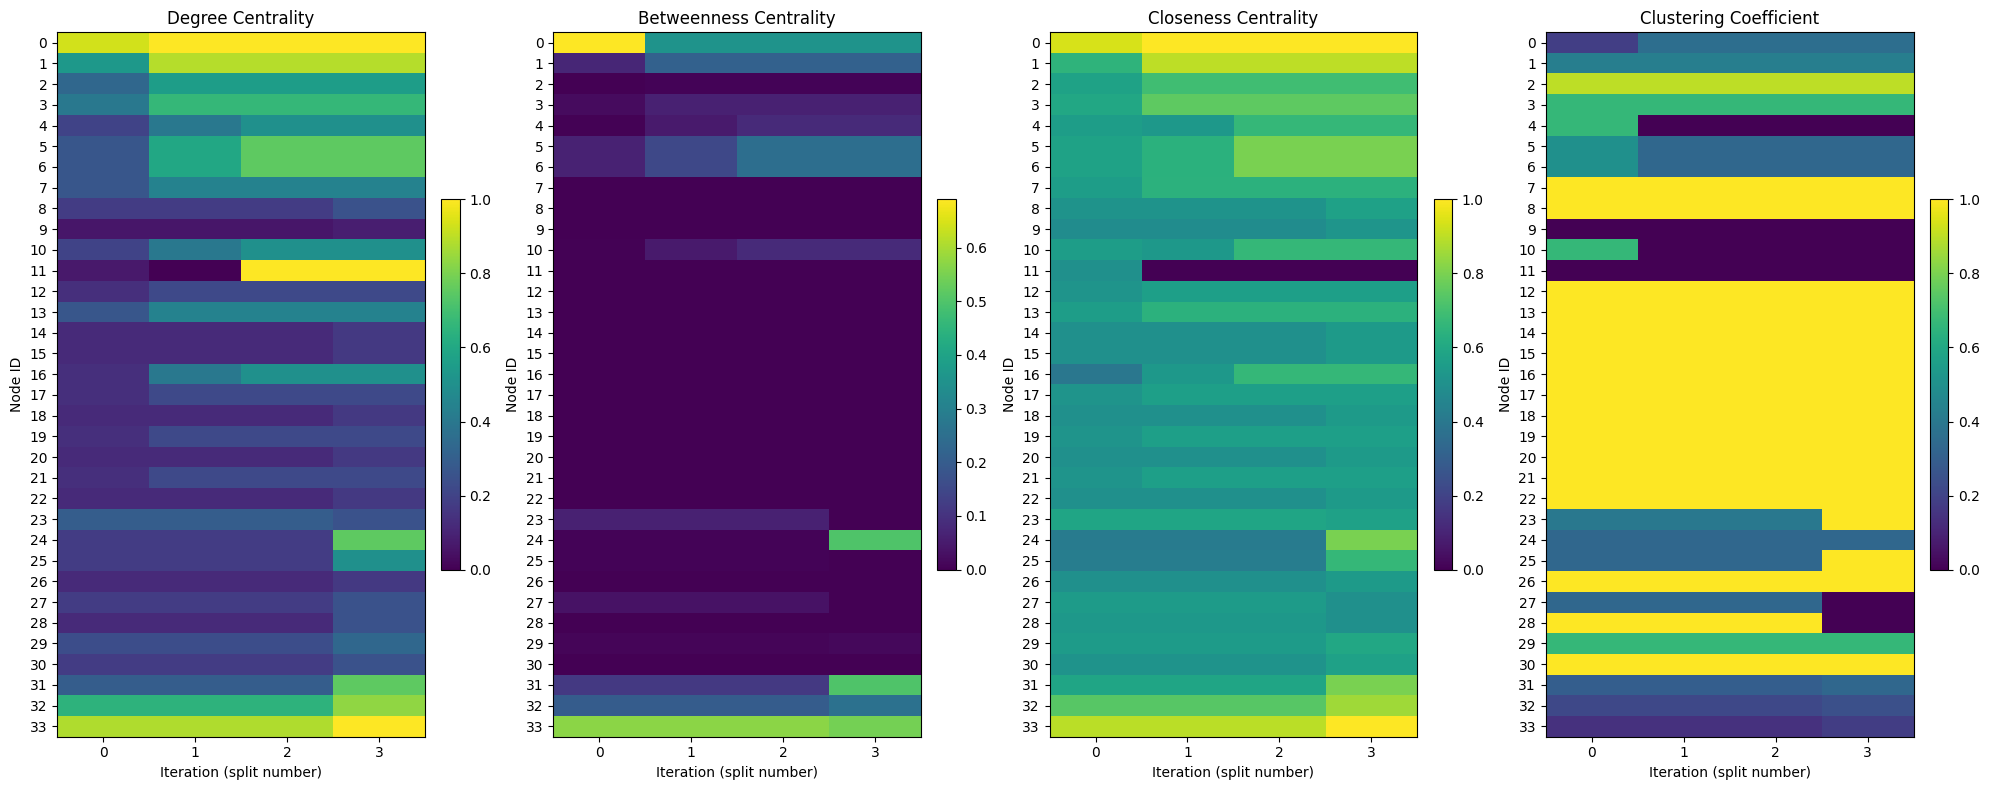

In [50]:


fig, axes = plt.subplots(1, 4, figsize=(20, 8))

for ax, (metric_name, metric_data) in zip(axes, metrics_history.items()):

    # Create a matrix: rows = nodes, columns = iterations
    data = np.array([
        [iteration[node] for iteration in metric_data]
        for node in G1.nodes()
    ])

    im = ax.imshow(data, aspect='auto', cmap='viridis')

    ax.set_title(metric_name)
    ax.set_xlabel("Iteration (split number)")
    ax.set_ylabel("Node ID")

    ax.set_xticks(range(len(partition_history)))
    ax.set_yticks(range(G1.number_of_nodes()))

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Step 13: Identify the five nodes with the highest average centrality

In [51]:


for metric_name in [
    "Degree Centrality",
    "Betweenness Centrality",
    "Closeness Centrality",
    "Clustering Coefficient"
]:

    metric_data = metrics_history[metric_name]

    average_values = {}

    for node in G1.nodes():
        values = [iteration[node] for iteration in metric_data]
        average_values[node] = np.mean(values)

    top_nodes = sorted(
        average_values.items(),
        key=lambda x: x[1],
        reverse=True
    )[:5]

    print("\n", metric_name)
    print("Top five nodes:", top_nodes)


 Degree Centrality
Top five nodes: [(0, np.float64(0.9833333333333334)), (33, np.float64(0.9117647058823529)), (1, np.float64(0.7999999999999999)), (32, np.float64(0.6936274509803921)), (3, np.float64(0.6))]

 Betweenness Centrality
Top five nodes: [(33, np.float64(0.5641209893048128)), (0, np.float64(0.43804563492063486)), (32, np.float64(0.21531305704099823)), (31, np.float64(0.20992647058823527)), (1, np.float64(0.17991071428571428))]

 Closeness Centrality
Top five nodes: [(0, np.float64(0.984375)), (33, np.float64(0.9210526315789473)), (1, np.float64(0.8380434782608696)), (32, np.float64(0.7686335403726708)), (3, np.float64(0.7125))]

 Clustering Coefficient
Top five nodes: [(7, np.float64(1.0)), (8, np.float64(1.0)), (12, np.float64(1.0)), (13, np.float64(1.0)), (14, np.float64(1.0))]


### **Discussion and Observations**

From the graphs and results, we observed the following:

1. **Degree centrality:** Nodes 33, 32 and 0 have more direct connections than most other nodes. Their values decrease as the graph is divided into smaller communities.

2. **Betweenness centrality:** Nodes 33 and 0 are important because they connect different parts of the network. Their values decrease after splitting because there are fewer paths between nodes in smaller communities.

3. **Closeness centrality:** Nodes 33, 32 and 0 can reach other nodes easily. Their closeness values generally decrease as the communities become smaller.

4. **Clustering coefficient:** Some nodes, such as 7, 14, 15, 16 and 18, have a clustering coefficient of 1. This means all their neighbours are connected to each other within their communities.

**Overall observation:**

Nodes 0 and 33 are important in the network because they have high values in several centrality measures. We also observed that when the graph is divided into smaller communities, the importance of some nodes changes. Some nodes become less central, while others remain important within their own communities.

The heatmaps and line graphs help us understand these changes clearly.

## **Conclusion**

In this assignment, we studied community detection using the Zachary Karate Club graph, which contains 34 nodes and 78 edges.

We implemented recursive spectral modularity partitioning to divide the graph into smaller communities. We used the modularity matrix and its leading eigenvector to identify the communities.

We also calculated four network metrics: degree centrality, betweenness centrality, closeness centrality and clustering coefficient.